<a href="https://colab.research.google.com/github/aniketguptarkg/Salary-Data-Analyzer/blob/main/Salary_data_analyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries loaded!")

Libraries loaded!


In [2]:
np.random.seed(42)   # makes random numbers repeatable (everyone gets the same data)
n = 200              # number of employees

departments = ["IT", "HR", "Sales", "Finance", "Marketing"]
cities = ["Delhi", "Mumbai", "Bengaluru", "Pune", "Hyderabad"]

df = pd.DataFrame({
    "employee_id": range(1, n + 1),
    "department": np.random.choice(departments, n),
    "city": np.random.choice(cities, n),
    "experience_years": np.random.randint(0, 21, n),
})

# Base monthly salary (in ₹) for each department
base_salary = {"IT": 40000, "HR": 30000, "Sales": 32000,
               "Finance": 38000, "Marketing": 34000}

# Salary = base + experience bonus + small random variation
df["salary"] = (
    df["department"].map(base_salary)
    + df["experience_years"] * np.random.randint(2000, 4000, n)
    + np.random.randint(-5000, 5000, n)
)

# Make some data "dirty" on purpose so we can practice cleaning
df.loc[[5, 20, 50, 120], "salary"] = np.nan

df.head()

,employee_id,department,city,experience_years,salary
0,1,Finance,Mumbai,15,85846.0
1,2,Marketing,Bengaluru,18,99856.0
2,3,Sales,Delhi,4,43396.0
3,4,Marketing,Delhi,13,79496.0
4,5,Marketing,Pune,4,46970.0


In [3]:
print("Shape (rows, columns):", df.shape)
print("\nColumn info:")
df.info()
print("\nMissing values:")
print(df.isnull().sum())
print("\nQuick statistics:")
df.describe()

Shape (rows, columns): (200, 5)

Column info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   employee_id       200 non-null    int64  
 1   department        200 non-null    object 
 2   city              200 non-null    object 
 3   experience_years  200 non-null    int64  
 4   salary            196 non-null    float64
dtypes: float64(1), int64(2), object(2)
memory usage: 7.9+ KB

Missing values:
employee_id         0
department          0
city                0
experience_years    0
salary              4
dtype: int64

Quick statistics:


,employee_id,experience_years,salary
count,200.000000,200.000000,196.000000
mean,100.500000,10.200000,65057.709184
std,57.879185,6.116129,19422.298249
min,1.000000,0.000000,25055.000000
25%,50.750000,4.000000,51200.250000
50%,100.500000,11.000000,63459.000000
75%,150.250000,16.000000,78140.750000
max,200.000000,20.000000,116164.000000


In [4]:
# Fill missing salaries with the median salary of that employee's department
df["salary"] = df["salary"].fillna(
    df.groupby("department")["salary"].transform("median")
)

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
employee_id         0
department          0
city                0
experience_years    0
salary              0
dtype: int64


In [5]:
# 1. Average salary per department
dept_avg = df.groupby("department")["salary"].mean().round(0).sort_values(ascending=False)
print("Average salary by department:\n", dept_avg)

# 2. Average salary per city
city_avg = df.groupby("city")["salary"].mean().round(0).sort_values(ascending=False)
print("\nAverage salary by city:\n", city_avg)

# 3. Top 5 highest-paid employees
print("\nTop 5 earners:")
print(df.sort_values("salary", ascending=False).head(5))

# 4. Does experience increase salary?
print("\nCorrelation (experience vs salary):",
      round(df["experience_years"].corr(df["salary"]), 2))

Average salary by department:
 department
IT           69221.0
Marketing    68080.0
Finance      65006.0
Sales        62782.0
HR           58582.0
Name: salary, dtype: float64

Average salary by city:
 city
Hyderabad    68659.0
Pune         65729.0
Delhi        64437.0
Mumbai       63262.0
Bengaluru    62971.0
Name: salary, dtype: float64

Top 5 earners:
     employee_id department       city  experience_years    salary
33            34         IT       Pune                19  116164.0
65            66    Finance      Delhi                20  112566.0
115          116  Marketing     Mumbai                20  106575.0
186          187  Marketing     Mumbai                20  105570.0
119          120         HR  Bengaluru                20  104011.0

Correlation (experience vs salary): 0.9


In [6]:
salaries = df["salary"].to_numpy()   # convert the column to a NumPy array

print("Average salary  :", round(np.mean(salaries)))
print("Median salary   :", round(np.median(salaries)))
print("Highest salary  :", round(np.max(salaries)))
print("Lowest salary   :", round(np.min(salaries)))
print("Std deviation   :", round(np.std(salaries)))
print("25th percentile :", round(np.percentile(salaries, 25)))
print("75th percentile :", round(np.percentile(salaries, 75)))

Average salary  : 64930
Median salary   : 63265
Highest salary  : 116164
Lowest salary   : 25055
Std deviation   : 19203
25th percentile : 51421
75th percentile : 77624


In [7]:
df["salary_band"] = pd.cut(
    df["salary"],
    bins=[0, 50000, 80000, 110000, np.inf],
    labels=["Low", "Medium", "High", "Very High"]
)

print(df["salary_band"].value_counts())

salary_band
Medium       114
Low           46
High          38
Very High      2
Name: count, dtype: int64


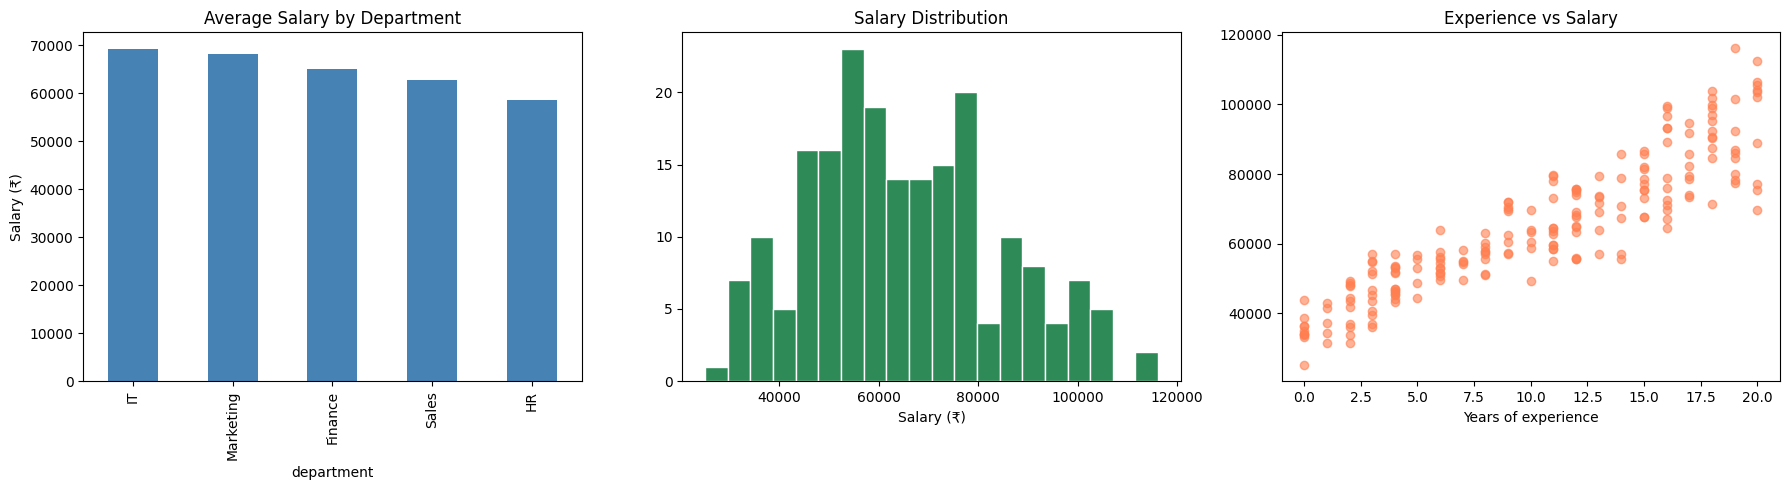

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: average salary by department
dept_avg.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Average Salary by Department")
axes[0].set_ylabel("Salary (₹)")

# Chart 2: salary distribution
axes[1].hist(df["salary"], bins=20, color="seagreen", edgecolor="white")
axes[1].set_title("Salary Distribution")
axes[1].set_xlabel("Salary (₹)")

# Chart 3: experience vs salary
axes[2].scatter(df["experience_years"], df["salary"], alpha=0.6, color="coral")
axes[2].set_title("Experience vs Salary")
axes[2].set_xlabel("Years of experience")

plt.tight_layout()
plt.savefig("salary_charts.png")   # saves the image
plt.show()

In [9]:
df.to_csv("salary_data_cleaned.csv", index=False)
dept_avg.to_csv("department_average_salary.csv")
print("Files saved!")

Files saved!
